In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
titanic_df = pd.read_csv("./train.csv")
titanic_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
titanic_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [4]:
titanic_df["Embarked"].head()

0    S
1    C
2    S
3    S
4    S
Name: Embarked, dtype: object

In [5]:
titanic_df["Age"] = titanic_df["Age"].fillna(titanic_df["Age"].mean())  # Age 결측값을을 평균으로 대체
titanic_df["Cabin"] = titanic_df["Cabin"].fillna("N")   # Cabin 결측값을 N으로 대체
titanic_df["Embarked"] = titanic_df["Embarked"].fillna("N") # Embarked 결측값을 N으로 대체
titanic_df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64

In [6]:
titanic_df["Sex"].value_counts()

male      577
female    314
Name: Sex, dtype: int64

In [7]:
titanic_df["Cabin"].value_counts()

N              687
C23 C25 C27      4
G6               4
B96 B98          4
C22 C26          3
              ... 
E34              1
C7               1
C54              1
E36              1
C148             1
Name: Cabin, Length: 148, dtype: int64

In [8]:
titanic_df["Embarked"].value_counts()

S    644
C    168
Q     77
N      2
Name: Embarked, dtype: int64

In [9]:
titanic_df["Cabin"] = titanic_df["Cabin"].str[:1]
titanic_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,N,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,N,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,N,S


In [10]:
titanic_df.groupby(["Sex", "Survived"])["Survived"].count()

Sex     Survived
female  0            81
        1           233
male    0           468
        1           109
Name: Survived, dtype: int64

<Axes: xlabel='Sex', ylabel='Survived'>

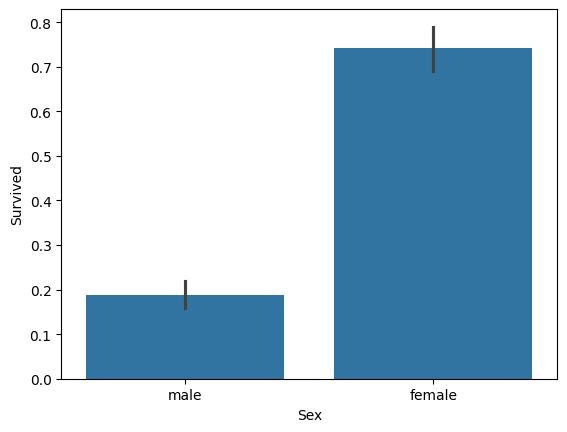

In [11]:
sns.barplot(x="Sex", y="Survived", data=titanic_df)

<Axes: xlabel='Pclass', ylabel='Survived'>

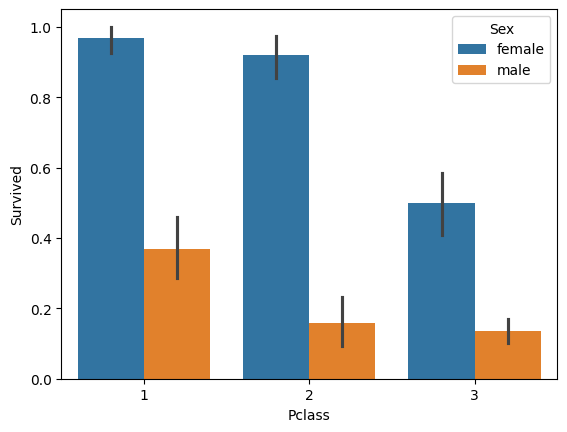

In [12]:
sns.barplot(x="Pclass", y="Survived", hue= "Sex", data = titanic_df)

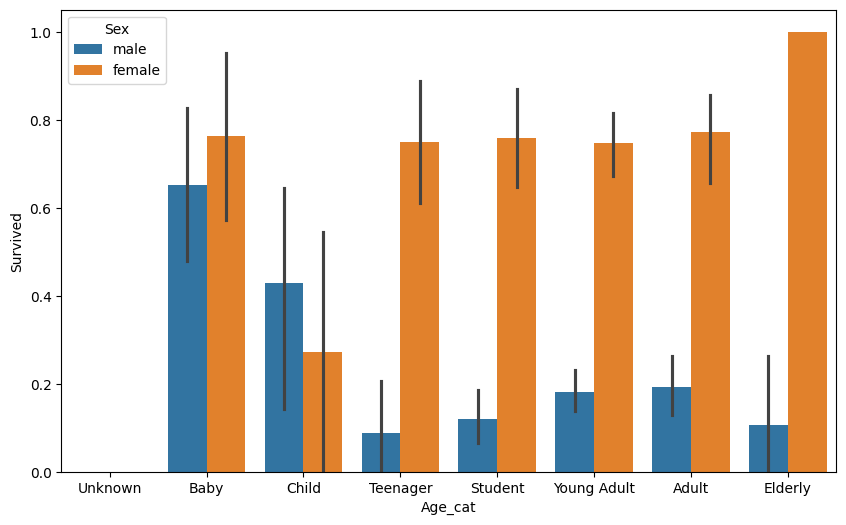

In [13]:
def get_category(age):  # 나이를 연령대 별로 분류
    cat = ""    
    if age <= -1: cat = "Unknown"
    elif age <= 5: cat = "Baby"
    elif age <= 12: cat = "Child"
    elif age <= 18: cat = "Teenager"
    elif age <= 25: cat = "Student"
    elif age <= 35: cat = "Young Adult"
    elif age <= 60: cat = "Adult"
    else: cat = "Elderly"

    return cat

group_name = ["Unknown", "Baby", "Child", "Teenager", "Student", "Young Adult", "Adult", "Elderly"] # 연령대 순서
titanic_df["Age_cat"] = titanic_df["Age"].apply(lambda x: get_category(x))  # Age를 연령대로 변환

plt.figure(figsize = (10, 6))   # 그래프 설정
sns.barplot(x= "Age_cat", y= "Survived", hue= "Sex", data = titanic_df, order= group_name)

titanic_df.drop("Age_cat", axis = 1, inplace = True)

In [14]:
from sklearn import preprocessing

def encode_features(df):    # # 범주형 데이터를 숫자로 변환하는 함수
    features = ["Cabin", "Sex", "Embarked"]
    for feature in features:
        le = preprocessing.LabelEncoder()   # encoder생성
        le = le.fit(df[feature])
        df[feature] = le.transform(df[feature]) # 문자 데이터를 숫자로 변환
    return df

titanic_df = encode_features(titanic_df)
titanic_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,7,3
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,2,0
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,7,3
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,2,3
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,7,3


In [15]:
titanic_df["Cabin"].value_counts()

7    687
2     59
1     47
3     33
4     32
0     15
5     13
6      4
8      1
Name: Cabin, dtype: int64

In [16]:
titanic_df["Sex"].value_counts()

1    577
0    314
Name: Sex, dtype: int64

In [17]:
titanic_df["Embarked"].value_counts()

3    644
0    168
2     77
1      2
Name: Embarked, dtype: int64

In [18]:
titanic_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,7,3
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,2,0
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,7,3
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,2,3
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,7,3


In [19]:
titanic_df.drop(["PassengerId", "Name", "Ticket"], axis = 1, inplace = True)

In [20]:
titanic_df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,0,3,1,22.0,1,0,7.2500,7,3
1,1,1,0,38.0,1,0,71.2833,2,0
2,1,3,0,26.0,0,0,7.9250,7,3
3,1,1,0,35.0,1,0,53.1000,2,3
4,0,3,1,35.0,0,0,8.0500,7,3


In [21]:
titanic_df["Fare"].isna().sum()

0

In [22]:
y_titanic_df = titanic_df["Survived"]
X_titanic_df = titanic_df.drop("Survived", axis = 1)

In [23]:
X_titanic_df.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,3,1,22.0,1,0,7.2500,7,3
1,1,0,38.0,1,0,71.2833,2,0
2,3,0,26.0,0,0,7.9250,7,3
3,1,0,35.0,1,0,53.1000,2,3
4,3,1,35.0,0,0,8.0500,7,3


In [24]:
y_titanic_df.head()

0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64

In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_titanic_df,
                                                    y_titanic_df, test_size = 0.2, random_state = 11)

In [26]:
from sklearn.tree import DecisionTreeClassifier # 결정트리 불러오기
from sklearn.ensemble import RandomForestClassifier # 랜덤포레스트 불러오기
from sklearn.linear_model import LogisticRegression # 로지스틱 불러오기
from sklearn.metrics import accuracy_score

df_clf = DecisionTreeClassifier(random_state=11)    # 결정트리 모델 생성
rf_clf = RandomForestClassifier(random_state=11)    # 랜덤포레스트 모델 생성
lr_clf = LogisticRegression(solver="liblinear")     # 로지스틱 모델 생성

df_clf.fit(X_train, y_train)    # 결정트리 모델 학습
df_pred = df_clf.predict(X_test)    # 결정트리 예측
print("결정트리 정확도:", accuracy_score(y_test, df_pred))

rf_clf.fit(X_train, y_train)    # 랜덤포레스트 모델 학습
rf_pred = rf_clf.predict(X_test)    # 랜덤포레스트 예측
print("랜덤포레스트 정확도:", accuracy_score(y_test, rf_pred))

lr_clf.fit(X_train, y_train)    # 로지스틱 모델 학습
lr_pred = lr_clf.predict(X_test)    # 로지스틱 예측
print("로지스틱 회귀 정확도:", accuracy_score(y_test, lr_pred))

결정트리 정확도: 0.7877094972067039
랜덤포레스트 정확도: 0.8547486033519553
로지스틱 회귀 정확도: 0.8659217877094972


In [27]:
from sklearn.model_selection import KFold

def exec_kfold(clf, folds = 5): # 모델과 분할 횟수를 입력받는 함수
    kfold = KFold(n_splits = folds) # 데이터를 지정한 횟수로 분할
    scores = []

    for iter_count, (train_index, test_index) in enumerate(kfold.split(X_titanic_df)):  # 학습용과 검증용 데이터 인덱스 생성
        X_train, X_test = X_titanic_df.values[train_index], X_titanic_df.values[test_index] # 특성 데이터 분할
        y_train, y_test = y_titanic_df.values[train_index], y_titanic_df.values[test_index] # 정답 데이터 분할

        clf.fit(X_train, y_train)   # 모델 학습
        predictions = clf.predict(X_test)   # 검증 데이터 예측
        accuracy = accuracy_score(y_test, predictions) # 정확도 계산
        scores.append(accuracy) # 정확도 저장
        print("교차검증정확도: ", accuracy)
    mean_score = np.mean(scores)
    print("평균 정확도:", mean_score)

exec_kfold(df_clf, 5)

교차검증정확도:  0.7541899441340782
교차검증정확도:  0.7808988764044944
교차검증정확도:  0.7865168539325843
교차검증정확도:  0.7696629213483146
교차검증정확도:  0.8202247191011236
평균 정확도: 0.782298662984119


In [28]:
exec_kfold(rf_clf, 5)

교차검증정확도:  0.7932960893854749
교차검증정확도:  0.8089887640449438
교차검증정확도:  0.8370786516853933
교차검증정확도:  0.7752808988764045
교차검증정확도:  0.8595505617977528
평균 정확도: 0.8148389931579938


In [29]:
from sklearn.model_selection import GridSearchCV

# 탐색할 파라미터와 값 설정
parameters = {"max_depth": [2, 3, 5, 10],
              "min_samples_split": [2, 3, 5],
              "min_samples_leaf": [1, 5, 8]
              }

grid_dclf = GridSearchCV(df_clf, param_grid=parameters,  # 파라미터 조합 탐색
                         scoring="accuracy", cv=5)  # 정확도 기준으로 5회 검증
grid_dclf.fit(X_train, y_train)  # 학습 데이터로 탐색

print(grid_dclf.best_params_)
print(grid_dclf.best_score_)

best_dclf = grid_dclf.best_estimator_  # 모델 저장

dpredictions = best_dclf.predict(X_test)  # 테스트 데이터 예측
accuracy = accuracy_score(y_test, dpredictions)  # 테스트 정확도 계산
print(accuracy)

{'max_depth': 3, 'min_samples_leaf': 5, 'min_samples_split': 2}
0.7991825076332119
0.8715083798882681
